# Workshop 3 - Reading the Gold layer (Team 2, Flood Monitoring and Risk, Texas)

The Gold DAG (`gold_flood_processing_dag`, PySpark) writes two summaries per run:

* `datalake_gold/governance_YYYYMMDD_HHMMSS.parquet` - data-quality KPIs (governance dashboard)
* `datalake_gold/storytelling_YYYYMMDD_HHMMSS.parquet` - analytical aggregations (functional-user dashboard)

Both are tidy tables: one row per value. A dashboard element is a filter on `kpi_name` (governance) or on
`section` + `metric` (storytelling). This notebook reads the newest pair with **Pandas** and previews the
content that Workshop 4 will draw with Plotly Dash.

In [1]:
from pathlib import Path
import json
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 70)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
GOLD = ROOT / "datalake_gold"
FIG = ROOT / "notebooks" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 9})
gov_file = sorted(GOLD.glob("governance_*.parquet"))[-1]
story_file = sorted(GOLD.glob("storytelling_*.parquet"))[-1]
gov, story = pd.read_parquet(gov_file), pd.read_parquet(story_file)
print(gov_file.name, gov.shape); print(story_file.name, story.shape)
print(pq.read_schema(gov_file).to_string(show_schema_metadata=False))

governance_20261117_192000.parquet (399, 14)
storytelling_20261117_192000.parquet (2294, 17)
kpi_group: string not null
kpi_name: string not null
topic: string
field: string
period_grain: string not null
period_start: date32[day]
value: double
numerator: int64
denominator: int64
unit: string not null
threshold: double
status: string
note: string
gold_run_ts: timestamp[ns] not null


## 1. Governance summary

In [2]:
gov.groupby(["kpi_group", "kpi_name"]).size().rename("rows").to_frame()

rows
kpi_group    kpi_name                            
accuracy     maintenance_flag_rate              5
             precip_source_share                2
completeness null_rate                        127
             sentinel_rate                      6
             station_day_completeness           5
text         encoding_repaired_rate             2
             language_distribution              2
             text_length_words                108
timeliness   ingestion_frequency_compliance    12
             ingestion_lag_hours                5
             record_lag_hours                   4
uniqueness   duplicate_rate_after_dedup         4
             duplicate_rate_before_dedup       11
             update_rate                        4
validity     outlier_rate                       8
             records_rejected                  20
             schema_compliance_files            4
             schema_compliance_records          4
volume       records_by_event_period           44
             records_ingested                   7
             records_ingested_cumulative        7
             records_total                      4
             silver_files                       4

In [3]:
headline = gov[(gov.period_grain == "all") & gov.kpi_name.isin([
    "records_total", "duplicate_rate_before_dedup", "duplicate_rate_after_dedup",
    "schema_compliance_files", "schema_compliance_records", "record_lag_hours"])]
headline.pivot_table(index="topic", columns="kpi_name", values="value").round(2)

kpi_name,duplicate_rate_after_dedup,duplicate_rate_before_dedup,record_lag_hours,records_total,schema_compliance_files,schema_compliance_records
topic,,,,,,
daily_precipitation,0.0,0.78,187.33,30786.0,100.0,99.99
flood_events,0.0,0.00,2804.03,8000.0,100.0,100.00
nws_alerts,0.0,66.48,4.88,61.0,100.0,100.00
nws_observations,0.0,43.21,0.75,372.0,100.0,100.00


In [4]:
nulls = gov[(gov.kpi_name == "null_rate") & (gov.value > 0)].sort_values("value", ascending=False)
nulls[["topic", "field", "value", "status", "note"]]

,topic,field,value,status,note
7,nws_observations,precip_3h_mm,100.0000,info,only reported in 3/6-hourly METAR
8,nws_observations,precip_6h_mm,100.0000,info,only reported in 6-hourly METAR
6,nws_observations,precip_1h_mm,85.2151,info,5-minute reports never carry rainfall (DQ #6)
23,nws_observations,severity_level,85.2151,info,undefined when the rainfall is unknown
100,daily_precipitation,prcp_zscore,77.7042,info,Z-score only computed on wet days (zero-inflated)
167,flood_events,impact_terms,58.7375,info,None
58,nws_alerts,reference_ids,44.2623,info,None
69,nws_alerts,impact_terms,37.7049,info,None
151,flood_events,damage_property_usd,0.7875,info,damage not estimated by NOAA (DQ #2)
152,flood_events,damage_crops_usd,0.5375,info,damage not estimated by NOAA (DQ #2)


In [5]:
gov[gov.kpi_name.isin(["outlier_rate", "encoding_repaired_rate", "language_distribution", "precip_source_share",
                        "maintenance_flag_rate", "station_day_completeness"])][
    ["kpi_name", "topic", "field", "value", "numerator", "denominator", "note"]]

,kpi_name,topic,field,value,numerator,denominator,note
246,outlier_rate,nws_observations,all_measurements,0.0000,0.0,372.0,flagged and kept: extremes are the flood signal
247,outlier_rate,nws_observations,precip_1h_mm,NaN,NaN,0.0,flagged and kept: extremes are the flood signal
248,outlier_rate,nws_observations,temperature_c,0.2688,1.0,372.0,flagged and kept: extremes are the flood signal
249,outlier_rate,daily_precipitation,"prcp_mm (IQR, k=3)",3.9336,270.0,6864.0,flagged and kept: extremes are the flood signal
250,outlier_rate,daily_precipitation,"prcp_mm (Z-score, |z|>3)",0.0874,6.0,6864.0,flagged and kept: extremes are the flood signal
251,outlier_rate,daily_precipitation,prcp_mm (NOAA quality flag),0.0000,0.0,30786.0,flagged and kept: extremes are the flood signal
252,outlier_rate,flood_events,damage_property_usd,3.8947,74.0,1900.0,flagged and kept: extremes are the flood signal
253,outlier_rate,flood_events,duration_hours,2.0625,165.0,8000.0,flagged and kept: extremes are the flood signal
326,language_distribution,flood_events,en,100.0000,8000.0,8000.0,heuristic stop-word language check
327,encoding_repaired_rate,flood_events,None,1.5625,125.0,8000.0,texts with U+FFFD replacement characters repaired in Silver


In [6]:
gov[gov.kpi_name == "ingestion_lag_hours"][["topic", "value", "threshold", "status", "note"]]

,topic,value,threshold,status,note
366,nws_alerts,0.33,0.5,ok,last successful pull 2026-11-17 19:00:00 UTC
367,storm_events_catalog,0.33,0.5,ok,last successful pull 2026-11-17 19:00:00 UTC
368,nws_observations,0.33,1.5,ok,last successful pull 2026-11-17 19:00:00 UTC
369,ghcnd,8.33,26.0,ok,last successful pull 2026-11-17 11:00:00 UTC
370,storm_events_details,8.33,26.0,ok,last successful pull 2026-11-17 11:00:00 UTC


In [7]:
ing = gov[gov.kpi_name == "ingestion_frequency_compliance"].pivot_table(index="period_start", columns="topic", values="value")
fail = gov[gov.status == "fail"]
print("KPIs with status 'fail':", len(fail)); ing.round(1)

KPIs with status 'fail': 0


topic,bronze_runs,ghcnd,nws_alerts,nws_observations,storm_events_catalog,storm_events_details
period_start,,,,,,
2026-11-16,2.1,100.0,2.1,4.2,2.1,100.0
2026-11-17,7.3,100.0,7.3,20.8,7.3,100.0


## 2. Storytelling summary

In [8]:
story.groupby(["section", "metric", "user_story"]).size().rename("rows").to_frame()

rows
section               metric                             user_story      
alerts                active_alert                       US1            2
                      alerts_last_7_days                 US1           13
                      alerts_last_7_days_by_county       US1           19
category_breakdown    events_by_event_type               US6            3
                      events_by_flood_cause              US6            6
                      events_by_report_source            US6           32
county_history        avg_severity                       US6          254
                      deaths                             US6          254
                      events_by_county_year              US6          235
                      floods_per_year                    US6          254
                      property_damage_usd                US6          254
current_rainfall      nws_rain_24h_mm                    US2            5
                      percentile_1d_vs_same_month        US3            5
                      percentile_7d_vs_same_month        US3            5
                      rain_1d_mm                         US2            5
                      rain_30d_mm                        US2            5
                      rain_7d_mm                         US2            5
flood_risk_index      fri_score                          US4            5
                      input_P24_percentile               US4            5
                      input_R24_mm                       US4            5
                      input_R7d_mm                       US4            5
                      input_alert_level                  US4            5
                      input_floods_per_year              US4            5
                      input_rain_level                   US4            5
                      input_top_quartile                 US4            5
fri_backtest          false_alarm_rate_pct               US4           24
                      hit_rate_pct                       US4           24
headline              counties_affected                  US6            1
                      deaths_total                       US6            1
                      flash_flood_share_pct              US6            1
                      flood_events_per_year              US6            1
                      flood_events_total                 US6            1
                      property_damage_usd                US6            1
keyword_severity      top_bigrams_severe_share_pct       US6           25
                      top_unigrams_severe_share_pct      US6           25
keywords              impact_terms                       US6           15
                      top_bigrams                        US6           25
                      top_unigrams                       US6           25
narrative             1_where                            US4/US6        1
                      2_when                             US4/US6        1
                      3_what                             US4/US6        1
                      4_now                              US4/US6        1
rain_climatology      daily_rain_p50                     US3           60
                      daily_rain_p90                     US3           60
                      daily_rain_p95                     US3           60
                      daily_rain_p99                     US3           60
                      wet_day_pct                        US3           60
seasonality           events_per_year_by_month           US6           12
severity_distribution alerts_by_event_type               US1            2
                      flood_events_by_severity           US6           53
source_comparison     records_and_avg_severity_by_source US5            4
trend                 damage_usd_per_month               US6          177
                      events_per_month                   US6          177

In [9]:
for line in story[story.section == "narrative"].sort_values("metric").label:
    print("-", line)
story[story.section == "headline"][["metric", "value", "label"]]

- Bexar County has the most flood reports since 2010 (322 events, 18.9 per year).
- May is the peak flood month (115.8 events per year on average).
- 80% of the events are flash floods; the most frequent two-word phrase in the narratives is 'heavy rain'.
- Highest current Flood Risk Index: HIGH in Nueces County (score 3, rainfall of 2026-11-10).


,metric,value,label
0,flood_events_total,8.000000e+03,2010-2026
1,flood_events_per_year,4.706000e+02,17 years
2,flash_flood_share_pct,8.040000e+01,Flash Flood events
3,property_damage_usd,4.899459e+10,reported property damage
4,deaths_total,4.320000e+02,direct + indirect
5,counties_affected,2.540000e+02,of 254 Texas counties


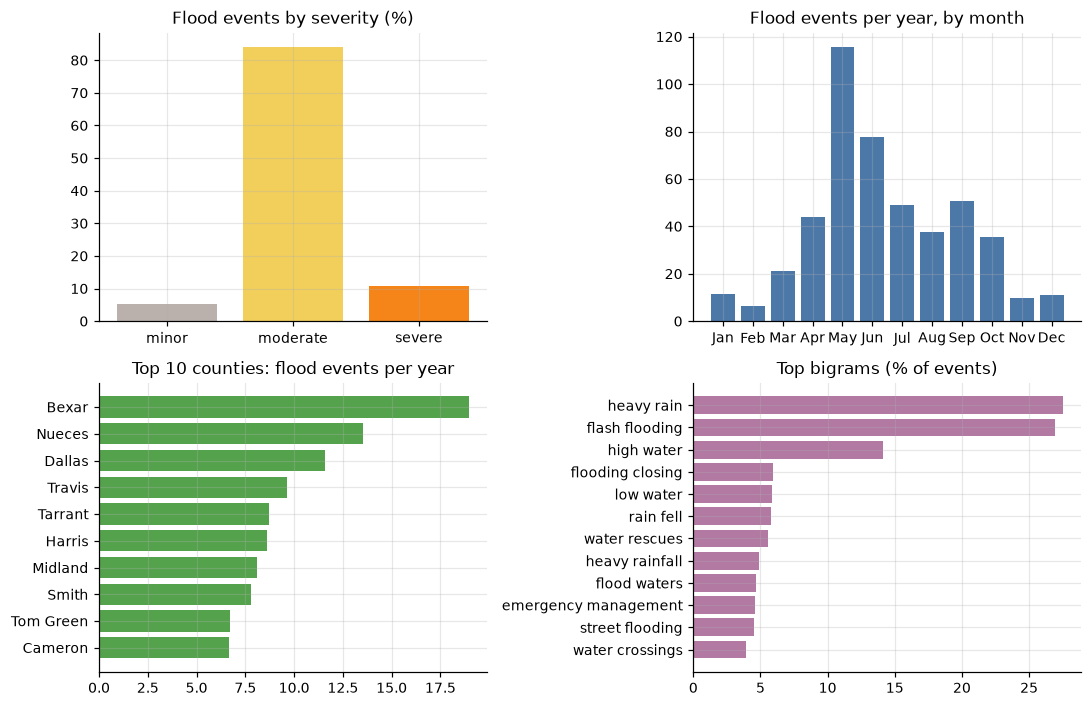

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
sev = story[(story.metric == "flood_events_by_severity") & (story.period_grain == "all")].sort_values("value")
axes[0, 0].bar(sev.category, sev.pct, color=["#BAB0AC", "#F2CF5B", "#F58518", "#E45756"][:len(sev)])
axes[0, 0].set_title("Flood events by severity (%)")
sea = story[story.section == "seasonality"].sort_values("rank")
axes[0, 1].bar(sea.category, sea.value, color="#4C78A8"); axes[0, 1].set_title("Flood events per year, by month")
top = story[(story.section == "county_history") & (story.metric == "floods_per_year")].nsmallest(10, "rank")
axes[1, 0].barh(top.county, top.value, color="#54A24B"); axes[1, 0].invert_yaxis()
axes[1, 0].set_title("Top 10 counties: flood events per year")
bg = story[(story.section == "keywords") & (story.metric == "top_bigrams")].nsmallest(12, "rank")
axes[1, 1].barh(bg.term, bg.pct, color="#B279A2"); axes[1, 1].invert_yaxis()
axes[1, 1].set_title("Top bigrams (% of events)")
fig.tight_layout(); fig.savefig(FIG / "w3_gold_storytelling_preview.png")

In [11]:
fri = story[story.section == "flood_risk_index"].pivot_table(index=["county", "station_id", "label"], columns="metric",
                                                            values="value").reset_index()
fri

metric,county,station_id,label,fri_score,input_P24_percentile,input_R24_mm,input_R7d_mm,input_alert_level,input_floods_per_year,input_rain_level,input_top_quartile
0,Bexar,KSAT,LOW,1.0,88.8,2.0,37.6,0.0,18.941,0.0,1.0
1,Harris,KIAH,LOW,1.0,77.5,0.3,23.4,0.0,8.588,0.0,1.0
2,Nueces,KCRP,HIGH,3.0,97.7,26.2,142.6,0.0,13.529,2.0,1.0
3,Tarrant,KDFW,LOW,1.0,83.8,0.5,0.5,0.0,8.706,0.0,1.0
4,Travis,KAUS,LOW,1.0,88.1,2.3,14.2,0.0,9.647,0.0,1.0


In [12]:
bt = story[(story.section == "fri_backtest") & (story.county == "ALL")]
bt.pivot_table(index=["term", "category"], columns="metric", values="value")

metric                                                   false_alarm_rate_pct  hit_rate_pct
term                                    category                                           
W1 rule: rain_level + top_quartile >= 2 test 2021-                      90.52         81.88
                                        train 2010-2020                 89.04         84.31
rain-only rule: rain_level >= 2         test 2021-                      86.15         73.19
                                        train 2010-2020                 84.39         71.90

In [13]:
story[(story.section == "alerts") & (story.metric == "active_alert")][["county", "category", "value", "label"]]

,county,category,value,label
2168,Mcmullen,Flood Warning,3.0,Severe | Flood Warning issued November 17 at 8:27AM CST until Nove...
2169,Mcmullen,Flood Warning,3.0,Severe | Flood Warning issued November 16 at 9:44AM CST until Nove...
